# ✅ Handling Missing Values in Categorical Features
# ✅ Strategy: Mode Imputation (Most Frequent)


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [4]:
# ==========================================================
# 1) Load Dataset
# ==========================================================

df = pd.read_csv('house.csv', usecols=['GarageQual','FireplaceQu','SalePrice'])

print("✅ Dataset Shape:", df.shape)
print(df.head(), "\n")

print("✅ Missing %:")
print(df.isnull().mean() * 100, "\n")

✅ Dataset Shape: (1460, 3)
  FireplaceQu GarageQual  SalePrice
0         NaN         TA     208500
1          TA         TA     181500
2          TA         TA     223500
3          Gd         TA     140000
4          TA         TA     250000 

✅ Missing %:
FireplaceQu    47.260274
GarageQual      5.547945
SalePrice       0.000000
dtype: float64 



✅ GarageQual value counts (before):
GarageQual
TA     1311
NaN      81
Fa       48
Gd       14
Ex        3
Po        3
Name: count, dtype: int64 



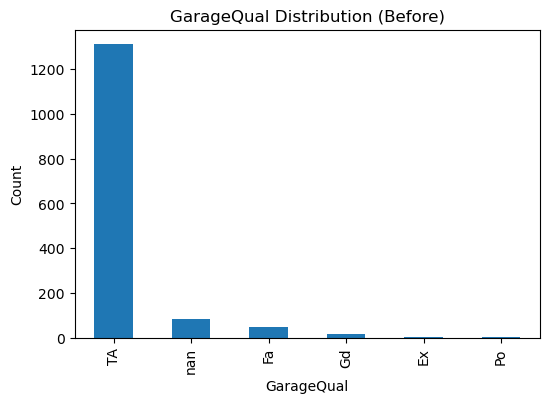

✅ GarageQual Mode: TA 



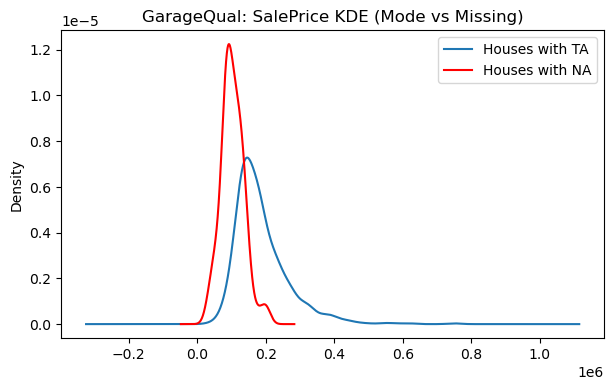

✅ GarageQual value counts (after):
GarageQual
TA    1392
Fa      48
Gd      14
Ex       3
Po       3
Name: count, dtype: int64 



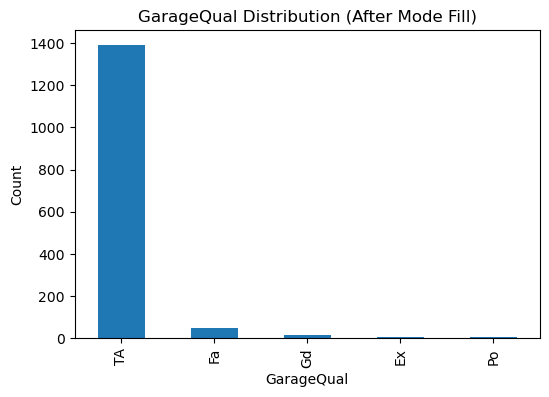

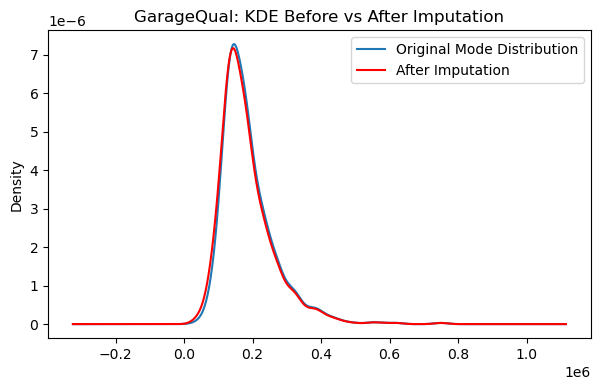

In [5]:
# ==========================================================
# 2) GarageQual Analysis (Before Imputation)
# ==========================================================

print("✅ GarageQual value counts (before):")
print(df['GarageQual'].value_counts(dropna=False), "\n")

df['GarageQual'].value_counts(dropna=False).plot(kind='bar', figsize=(6,4))
plt.title("GarageQual Distribution (Before)")
plt.xlabel("GarageQual")
plt.ylabel("Count")
plt.show()

# Mode of GarageQual
garage_mode = df['GarageQual'].mode()[0]
print("✅ GarageQual Mode:", garage_mode, "\n")

# KDE Comparison: TA vs Missing
fig = plt.figure(figsize=(7,4))
ax = fig.add_subplot(111)

df[df['GarageQual'] == garage_mode]['SalePrice'].plot(kind='kde', ax=ax, label=f'Houses with {garage_mode}')
df[df['GarageQual'].isnull()]['SalePrice'].plot(kind='kde', ax=ax, color='red', label='Houses with NA')

plt.title("GarageQual: SalePrice KDE (Mode vs Missing)")
plt.legend()
plt.show()

# Save original distribution (only TA rows)
temp_garage = df[df['GarageQual'] == garage_mode]['SalePrice']

# Impute GarageQual with mode
df = df.copy()
df['GarageQual'] = df['GarageQual'].fillna(garage_mode)

print("✅ GarageQual value counts (after):")
print(df['GarageQual'].value_counts(dropna=False), "\n")

df['GarageQual'].value_counts(dropna=False).plot(kind='bar', figsize=(6,4))
plt.title("GarageQual Distribution (After Mode Fill)")
plt.xlabel("GarageQual")
plt.ylabel("Count")
plt.show()

# KDE after imputation
fig = plt.figure(figsize=(7,4))
ax = fig.add_subplot(111)

temp_garage.plot(kind='kde', ax=ax, label="Original Mode Distribution")
df[df['GarageQual'] == garage_mode]['SalePrice'].plot(kind='kde', ax=ax, color='red', label="After Imputation")

plt.title("GarageQual: KDE Before vs After Imputation")
plt.legend()
plt.show()


✅ FireplaceQu value counts (before):
FireplaceQu
NaN    690
Gd     380
TA     313
Fa      33
Ex      24
Po      20
Name: count, dtype: int64 



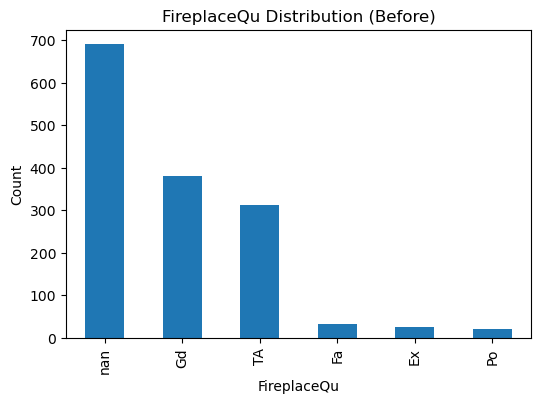

✅ FireplaceQu Mode: Gd 



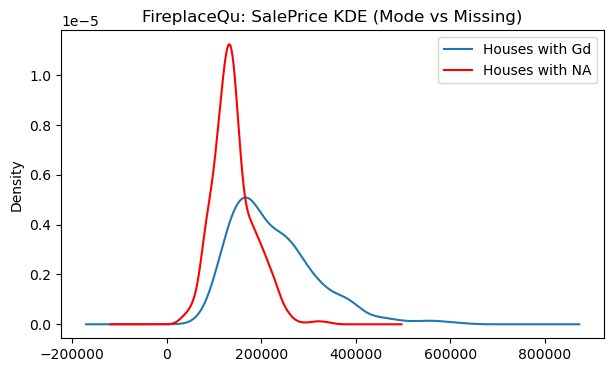

✅ FireplaceQu value counts (after):
FireplaceQu
Gd    1070
TA     313
Fa      33
Ex      24
Po      20
Name: count, dtype: int64 



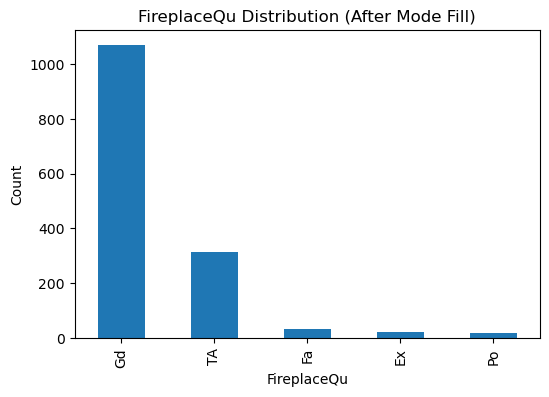

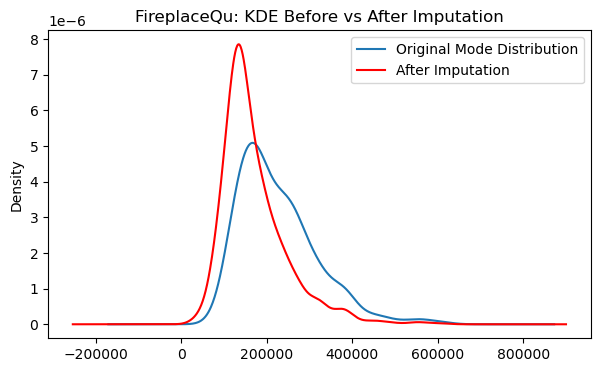

In [6]:

# ==========================================================
# 3) FireplaceQu Analysis (Before Imputation)
# ==========================================================

print("✅ FireplaceQu value counts (before):")
print(df['FireplaceQu'].value_counts(dropna=False), "\n")

df['FireplaceQu'].value_counts(dropna=False).plot(kind='bar', figsize=(6,4))
plt.title("FireplaceQu Distribution (Before)")
plt.xlabel("FireplaceQu")
plt.ylabel("Count")
plt.show()

# Mode of FireplaceQu
fire_mode = df['FireplaceQu'].mode()[0]
print("✅ FireplaceQu Mode:", fire_mode, "\n")

# KDE Comparison: Mode vs Missing
fig = plt.figure(figsize=(7,4))
ax = fig.add_subplot(111)

df[df['FireplaceQu'] == fire_mode]['SalePrice'].plot(kind='kde', ax=ax, label=f'Houses with {fire_mode}')
df[df['FireplaceQu'].isnull()]['SalePrice'].plot(kind='kde', ax=ax, color='red', label='Houses with NA')

plt.title("FireplaceQu: SalePrice KDE (Mode vs Missing)")
plt.legend()
plt.show()

# Save original distribution (only mode rows)
temp_fire = df[df['FireplaceQu'] == fire_mode]['SalePrice']

# Impute FireplaceQu with mode
df['FireplaceQu'] = df['FireplaceQu'].fillna(fire_mode)

print("✅ FireplaceQu value counts (after):")
print(df['FireplaceQu'].value_counts(dropna=False), "\n")

df['FireplaceQu'].value_counts(dropna=False).plot(kind='bar', figsize=(6,4))
plt.title("FireplaceQu Distribution (After Mode Fill)")
plt.xlabel("FireplaceQu")
plt.ylabel("Count")
plt.show()

# KDE after imputation
fig = plt.figure(figsize=(7,4))
ax = fig.add_subplot(111)

temp_fire.plot(kind='kde', ax=ax, label="Original Mode Distribution")
df[df['FireplaceQu'] == fire_mode]['SalePrice'].plot(kind='kde', ax=ax, color='red', label="After Imputation")

plt.title("FireplaceQu: KDE Before vs After Imputation")
plt.legend()
plt.show()

In [7]:
# ==========================================================
# 4) Using Sklearn SimpleImputer (Most Frequent)
# ==========================================================

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

X = df.drop(columns=['SalePrice'])
y = df['SalePrice']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

imputer = SimpleImputer(strategy='most_frequent')

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)   # ✅ FIXED (X_test pe apply hoga)

print("✅ Imputer statistics_ (most frequent for each column):")
print(imputer.statistics_)

✅ Imputer statistics_ (most frequent for each column):
['Gd' 'TA']
